# FNEWS — Evaluation, calibration, and robustness

**Research objective.** Matched validation comparison, error analysis, calibration and robustness evidence, then a clearly bounded final summary.

This consolidated notebook reuses saved, executed research evidence. It does not train models or perform new held-out-test selection. `SOURCE_TRUE` and `SOURCE_NON_TRUE` are Fakeddit source-taxonomy labels, not independent real-world fact-checking verdicts.

In [ ]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd()
if not (ROOT / "data/research_dataset").exists():
    ROOT = Path("/Users/aka_ank/Desktop/FNEWS")
DATA = ROOT / "data/research_dataset"
REPORTS = ROOT / "reports"
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.titlesize": 13, "axes.labelsize": 11})

def paired(split):
    frame = pd.read_parquet(DATA / "manifests" / f"{split}_manifest.parquet")
    return frame.loc[(frame.source_dataset == "Fakeddit") & (frame.download_status == "verified_reused_or_processed")].copy().reset_index(drop=True)

def canonical_source_labels(raw):
    """Fakeddit raw 1=true; return 0=SOURCE_TRUE, 1=SOURCE_NON_TRUE."""
    return 1 - np.asarray(raw, dtype=int)

def source_names(values):
    return np.where(np.asarray(values) == 0, "SOURCE_TRUE", "SOURCE_NON_TRUE")

def show_frame(frame, rows=10):
    display(frame.head(rows))


## Matched model evaluation

_Source preserved from `notebooks/archive/2026-10-27/research/07_model_evaluation.ipynb`._

## Evaluation protocol

Macro-F1 weights both classes equally, which is valuable when source-taxonomy classes differ in frequency. Accuracy alone can hide asymmetric errors. All comparisons below use the same 933 validation IDs and are not external factuality scores.

In [2]:
from sklearn.metrics import confusion_matrix,precision_recall_fscore_support,accuracy_score,f1_score
paths={'LinearSVC':REPORTS/'experiments/research_dataset_baselines/tfidf_svm/validation_predictions.parquet','Frozen pretrained text':REPORTS/'experiments/research_dataset_baselines/pretrained_text_frozen/validation_predictions.parquet','ResNet-18':REPORTS/'experiments/research_dataset_baselines/resnet18_frozen/validation_predictions.parquet','Weighted fusion':REPORTS/'weighted_late_fusion_v1/validation_predictions.parquet','CLIP gated (archived)':REPORTS/'multimodal_fusion/clip_fusion_v1/gated/validation_predictions.parquet'}
rows=[]
for name,path in paths.items():
 d=pd.read_parquet(path);y=canonical_source_labels(d.label);p=canonical_source_labels(d.prediction);cm=confusion_matrix(y,p,labels=[0,1]);rows.append({'model':name,'ids':d.sample_id.nunique(),'accuracy':accuracy_score(y,p),'macro_f1':f1_score(y,p,average='macro'),'true_recall':cm[0,0]/cm[0].sum(),'non_true_recall':cm[1,1]/cm[1].sum(),'balanced_accuracy':np.mean([cm[0,0]/cm[0].sum(),cm[1,1]/cm[1].sum()]),'matrix':cm.tolist()})
comparison=pd.DataFrame(rows);display(comparison.sort_values('macro_f1',ascending=False))

,model,ids,accuracy,macro_f1,true_recall,non_true_recall,balanced_accuracy,matrix
4,CLIP gated (archived),933,0.874598,0.870700,0.867374,0.879496,0.873435,"[[327, 50], [67, 489]]"
3,Weighted fusion,933,0.764202,0.759459,0.771883,0.758993,0.765438,"[[291, 86], [134, 422]]"
0,LinearSVC,933,0.720257,0.717136,0.761273,0.692446,0.726860,"[[287, 90], [171, 385]]"
1,Frozen pretrained text,933,0.691318,0.688974,0.748011,0.652878,0.700444,"[[282, 95], [193, 363]]"
2,ResNet-18,933,0.693462,0.686088,0.668435,0.710432,0.689433,"[[252, 125], [161, 395]]"


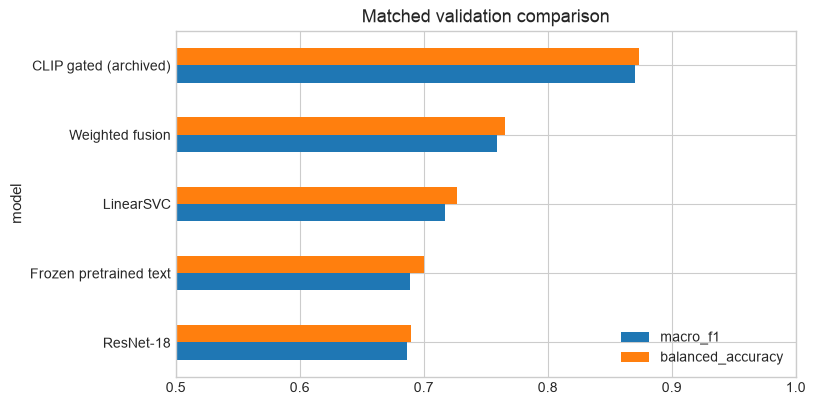

In [3]:
fig,ax=plt.subplots();comparison.set_index('model')[['macro_f1','balanced_accuracy']].sort_values('macro_f1').plot.barh(ax=ax,title='Matched validation comparison');ax.set_xlim(.5,1);plt.show()

## Frozen test record

A previously recorded single test result exists for the archived gated model (86.91% accuracy, 86.45% macro-F1 on 947 pairs). It is historical, was not reread here, and was not used for selection.

## Error analysis

_Source preserved from `notebooks/archive/2026-10-27/research/08_error_analysis.ipynb`._

## Active SVM errors

The corrected canonical matrix is `[[287, 90], [171, 385]]` in `[SOURCE_TRUE, SOURCE_NON_TRUE]` order. Correct label presentation did not change these raw predictions.

In [2]:
fn=pd.read_csv(REPORTS/'root_cause/svm_source_non_true_false_negatives.csv');fp=pd.read_csv(REPORTS/'root_cause/false_positive_manifest.csv');print('SOURCE_NON_TRUE → SOURCE_TRUE:',len(fn));print('SOURCE_TRUE → SOURCE_NON_TRUE:',len(fp));display(fn.head(10))

SOURCE_NON_TRUE → SOURCE_TRUE: 171
SOURCE_TRUE → SOURCE_NON_TRUE: 90


,sample_id,text,subreddit,domain,6_way_label,text_length,source_non_true_margin,failure_category
0,fakeddit:validate:3b9bxa,brazilian police with riot shields,misleadingthumbnails,i.imgur.com,2,34,-1.503464,source_non_true_to_true
1,fakeddit:validate:en2chek,this cat out of a box,psbattle_artwork,NaN,4,21,-1.488794,source_non_true_to_true
2,fakeddit:validate:cucs6vt,this,psbattle_artwork,NaN,4,4,-1.450561,source_non_true_to_true
3,fakeddit:validate:caeb30f,this,psbattle_artwork,NaN,4,4,-1.450561,source_non_true_to_true
4,fakeddit:validate:66plgc,former president barack obama spotted outside ...,fakehistoryporn,pbs.twimg.com,2,102,-1.281586,source_non_true_to_true
5,fakeddit:validate:7vtjnz,home of sexuals magnets,fakealbumcovers,i.redd.it,1,23,-1.269571,source_non_true_to_true
6,fakeddit:validate:47opgx,kizuna takahara when your roommate works at di...,subredditsimulator,imgur.com,3,72,-1.187837,source_non_true_to_true
7,fakeddit:validate:dzi2974,cat scan,psbattle_artwork,NaN,4,8,-1.181896,source_non_true_to_true
8,fakeddit:validate:au8e59,cat,misleadingthumbnails,i.redd.it,2,3,-1.181896,source_non_true_to_true
9,fakeddit:validate:911c67,robot peering out of an elevator shaft,misleadingthumbnails,i.redd.it,2,38,-1.154207,source_non_true_to_true


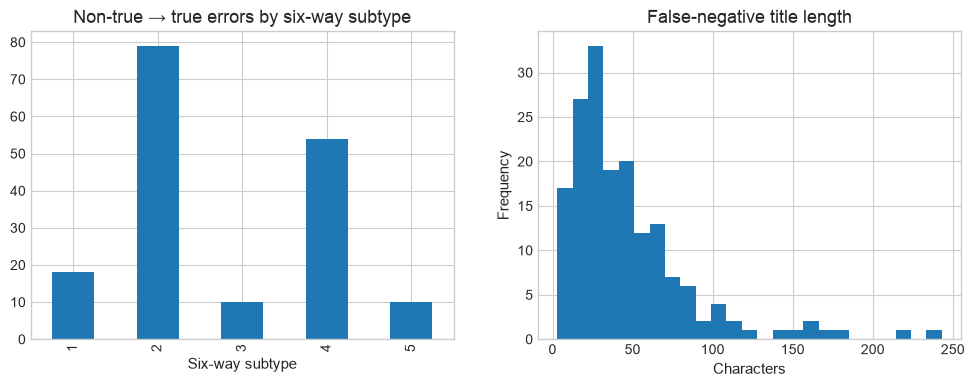

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4));fn['6_way_label'].value_counts().sort_index().plot.bar(ax=axes[0],title='Non-true → true errors by six-way subtype');axes[0].set_xlabel('Six-way subtype');fn.text_length.plot.hist(ax=axes[1],bins=25,title='False-negative title length');axes[1].set_xlabel('Characters');plt.show()

In [4]:
display(fn.groupby('subreddit').size().sort_values(ascending=False).head(12).rename('errors').to_frame());display(fn.sort_values('source_non_true_margin').head(12)[['text','subreddit','6_way_label','source_non_true_margin']])

,errors
subreddit,
psbattle_artwork,54
pareidolia,31
fakehistoryporn,25
misleadingthumbnails,15
subredditsimulator,10
confusing_perspective,8
fakealbumcovers,7
propagandaposters,6
satire,5


,text,subreddit,6_way_label,source_non_true_margin
0,brazilian police with riot shields,misleadingthumbnails,2,-1.503464
1,this cat out of a box,psbattle_artwork,4,-1.488794
2,this,psbattle_artwork,4,-1.450561
3,this,psbattle_artwork,4,-1.450561
4,former president barack obama spotted outside ...,fakehistoryporn,2,-1.281586
5,home of sexuals magnets,fakealbumcovers,1,-1.269571
6,kizuna takahara when your roommate works at di...,subredditsimulator,3,-1.187837
7,cat scan,psbattle_artwork,4,-1.181896
8,cat,misleadingthumbnails,2,-1.181896
9,robot peering out of an elevator shaft,misleadingthumbnails,2,-1.154207


## Interpretation

Failures include satire, misleading content, imposter content, false connection, and manipulation. Short titles and source-community style can limit lexical evidence. These labels are taxonomy categories, not universal fact-check outcomes; no record is relabeled in this notebook.

## Calibration and robustness

_Source preserved from `notebooks/archive/2026-10-27/research/09_robustness_calibration.ipynb`._

## Calibration

Temperature scaling maps logits to probabilities using a learned positive temperature. ECE measures calibration gap; Brier score measures squared probability error. Calibration does not establish factuality or repair domain shift.

In [2]:
cal=json.loads((REPORTS/'phase2/calibration/metrics.json').read_text());display(pd.json_normalize(cal));print('Saved temperature:',json.loads((REPORTS/'phase2/calibration/temperature.json').read_text()).get('temperature'))

,temperature,protocol.split,protocol.calibration_samples,protocol.assessment_samples,protocol.seed,protocol.heldout_test_accessed,assessment_raw.ece_10,assessment_raw.brier,assessment_raw.negative_log_likelihood,assessment_calibrated.ece_10,assessment_calibrated.brier,assessment_calibrated.negative_log_likelihood,calibration_raw.ece_10,calibration_raw.brier,calibration_raw.negative_log_likelihood,calibration_calibrated.ece_10,calibration_calibrated.brier,calibration_calibrated.negative_log_likelihood
0,2.532525,Fakeddit validation only,466,467,42,False,0.088905,0.101671,0.386519,0.037953,0.089823,0.287592,0.085325,0.111534,0.48317,0.052858,0.10446,0.337817


Saved temperature: 2.532524824142456


The saved assessment used 467 validation examples: ECE improved from 0.0889 to 0.0380 and Brier score from 0.1017 to 0.0898. This is a split-local calibration assessment.

In [3]:
ablation=json.loads((REPORTS/'phase2/modality_ablation/metrics.json').read_text());display(pd.DataFrame(ablation['conditions']).T)

,accuracy,macro_f1,prediction_change_rate_vs_paired,mean_absolute_probability_shift_vs_paired,gate_mean_text_weight,gate_std_text_weight,image_projection_norm_mean,text_projection_norm_mean,class_prediction_change_rate,bootstrap_macro_f1_delta_vs_shuffled_image_95ci,bootstrap_macro_f1_delta_vs_shuffled_text_95ci
paired,0.874598,0.8707,0.0,0.0,0.519165,0.190218,9.135094,9.668982,"{'0': 0.0, '1': 0.0}","[0.1300029233904467, 0.19437877376788446]","[0.19831487769257267, 0.263212666993924]"
shuffled_image,0.726688,0.707665,0.257235,0.249307,0.519329,0.191306,9.135095,9.668982,"{'0': 0.17446043165467626, '1': 0.379310344827...",NaN,NaN
shuffled_text,0.65702,0.638162,0.303323,0.298586,0.519188,0.191578,9.135094,9.668981,"{'0': 0.23741007194244604, '1': 0.400530503978...",NaN,NaN


## Robustness

Frozen modality shuffling changes macro-F1 from 87.07% paired to 70.77% with shuffled images and 63.82% with shuffled text. The raw-image sweep is a 32-pair, 19-condition subset experiment—not a full-validation robustness estimate. Severe blur sigma 3 changed subset macro-F1 from 87.50% to 77.03%.

In [4]:
paths=list((REPORTS/'phase2').rglob('*robust*.json'));print('Available robustness JSON:',[p.name for p in paths]);
for path in paths:
 print('\n',path);display(pd.json_normalize(json.loads(path.read_text())).head())

Available robustness JSON: []


## Conclusions and limitations

_Source preserved from `notebooks/archive/2026-10-27/research/10_final_research_summary.ipynb`._

## Problem, objective, and pipeline

FNEWS studies source-taxonomy classification of paired Reddit text and images. The pipeline is: official metadata → verified bounded pairs → leakage controls → train-only preprocessing → saved baselines/fusion experiments → validation-only diagnostics → guarded local URL/text workflow. It is not a general-purpose factual-truth verifier.

## EDA totals at a glance

The dataset EDA confirms that this research version contains only verified text-image pairs. Fakeddit raw label `1` maps to `SOURCE_TRUE`; raw label `0` maps to the broader `SOURCE_NON_TRUE` taxonomy. The diagram below is an EDA summary, not a performance chart.

In [ ]:
splits={s:paired(s) for s in ['train','validate']}
eda=pd.DataFrame([{'split':s.title(),'pairs':len(frame),'SOURCE_TRUE':int((frame.fake_news_label==1).sum()),'SOURCE_NON_TRUE':int((frame.fake_news_label==0).sum())} for s,frame in splits.items()]);display(eda)
print('Total verified paired samples:',int(eda.pairs.sum()))
print('Total SOURCE_TRUE:',int(eda.SOURCE_TRUE.sum()),'| Total SOURCE_NON_TRUE:',int(eda.SOURCE_NON_TRUE.sum()))

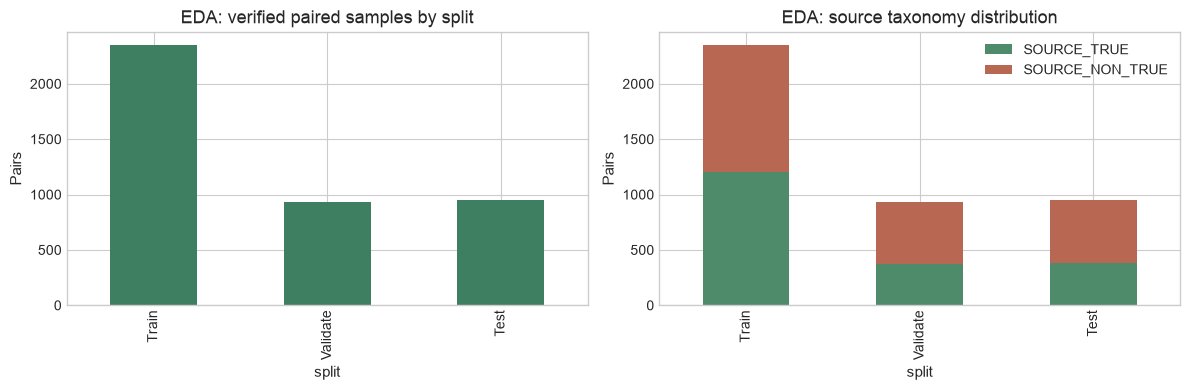

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4));eda.set_index('split')['pairs'].plot.bar(ax=axes[0],color='#3f7f61',title='EDA: verified paired samples by split');axes[0].set_ylabel('Pairs')
eda.set_index('split')[['SOURCE_TRUE','SOURCE_NON_TRUE']].plot.bar(stacked=True,ax=axes[1],color=['#4e8b6a','#b86753'],title='EDA: source taxonomy distribution');axes[1].set_ylabel('Pairs');plt.tight_layout();plt.show()

## Training methodology

**Text baseline.** The active TF-IDF + LinearSVC model learns a maximum-margin decision boundary from cleaned Fakeddit titles. The vectorizer is fitted on training text only with up to 50,000 unigram/bigram features, `min_df=2`, sublinear term frequency, and L2 normalization. A LinearSVC margin is not a calibrated probability.

**Image baseline.** ResNet-18 uses ImageNet preprocessing and a two-class head on local images. Image-only results are limited because an image cannot independently establish the factual status of a title.

**Fusion experiments.** Weighted late fusion combines compatible calibrated source-non-true probabilities with alpha 0.41/0.59. CLIP gated fusion combines frozen 512-D image and text embeddings with a learned feature-wise sigmoid gate. Both are retained research artifacts; the latter is archived/inactive in the website.

In [4]:
svm=joblib.load(REPORTS/'experiments/research_dataset_baselines/tfidf_svm/model.joblib');print('Saved TF-IDF + LinearSVC configuration:');print(svm)
history=pd.read_csv(REPORTS/'experiments/research_dataset_baselines/resnet18_frozen/history.csv');print('ResNet history columns:',history.columns.tolist());print('Weighted late-fusion alpha:',json.loads((REPORTS/'weighted_late_fusion_v1/metrics.json').read_text())['alpha'])

Saved TF-IDF + LinearSVC configuration:
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=50000, min_df=2,
                                 ngram_range=(1, 2), sublinear_tf=True)),
                ('svm', LinearSVC())])
ResNet history columns: ['epoch', 'train_loss', 'validation_macro_f1']
Weighted late-fusion alpha: 0.41000000000000003


In [5]:
state=json.loads((ROOT/'PROJECT_STATE.json').read_text());display(pd.DataFrame(state['phase_status_checklist']))

,phase,status,evidence,metrics,next_action
0,Validated Fakeddit research dataset,completed,"4,233 verified pairs; leakage report; 0.158 GiB","2,353/933/947 train/validation/test",Preserve split and 20 GiB cap
1,Frozen gated-fusion baseline,completed,checkpoint hash and saved metrics verified,"validation 87.46% accuracy, 87.07% macro-F1; h...",Do not tune on test
2,Secure URL multimodal inference,completed,controlled URL-to-fusion workflow plus runtime...,85 tests passed; API smoke exposed non_true/tr...,Use only with explicit research-label warning
3,External compatibility and acquisition,completed,five-candidate review; ReCOVery 100-record pilot,"66 validated pairs, 34 inaccessible images",Retain source labels; seek compatible split-de...
4,External zero-shot evaluation,deferred,intentionally deferred by user; prior data/lab...,not measured,Do not perform external discovery or evaluatio...
5,Modality contribution,completed,frozen 933-sample validation perturbation run,paired 87.07 macro-F1; shuffled image 70.77; s...,Use only as sensitivity evidence
6,Probability calibration,completed,stratified validation-half fit and assessment,assessment ECE 0.0889→0.0380; Brier 0.1017→0.0898,Monitor transfer before relying on calibrated ...
7,Explainability,in_progress,gate/norm/perturbation diagnostics executed,mean text gate 0.519 ± 0.190,Run registered raw-image and token attribution...
8,Robustness,in_progress,16-pair pilot and independent 32-pair 19-condi...,32-pair blur sigma 3 macro-F1 77.03%; full par...,Decide whether a registered full-partition or ...
9,Live-publisher URL QA,blocked,Reuters/AP access denials and Guardian Develop...,zero authorized compatible publisher inputs af...,Resume only with a source explicitly authorizi...


,accuracy,macro_f1,source_true_recall,source_non_true_recall,balanced_accuracy,matrix
TF-IDF + LinearSVC (active),0.720257,0.717136,0.761273,0.692446,0.72686,"[[287, 90], [171, 385]]"
ResNet-18 frozen,0.693462,0.686088,0.668435,0.710432,0.689433,"[[252, 125], [161, 395]]"
Weighted late fusion,0.764202,0.759459,0.771883,0.758993,0.765438,"[[291, 86], [134, 422]]"
CLIP gated fusion (archived),0.874598,0.8707,0.867374,0.879496,0.873435,"[[327, 50], [67, 489]]"


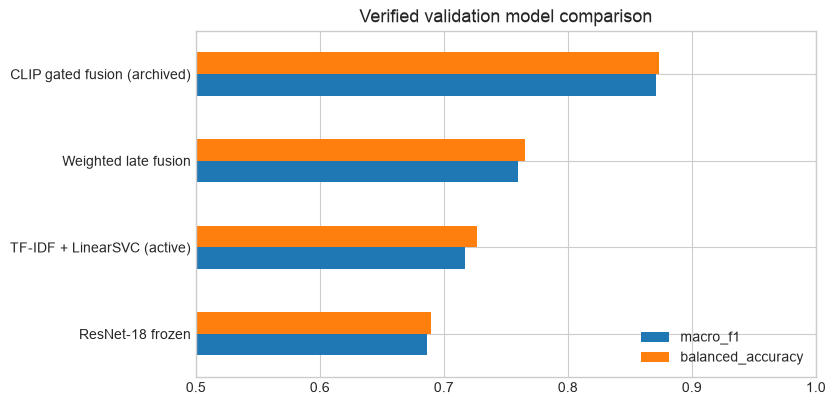

In [6]:
reliability=json.loads((REPORTS/'root_cause/classification_reliability_metrics.json').read_text());comparison=pd.DataFrame(reliability['model_metrics']).T;display(comparison[['accuracy','macro_f1','source_true_recall','source_non_true_recall','balanced_accuracy','matrix']])
comparison[['macro_f1','balanced_accuracy']].sort_values('macro_f1').plot.barh(title='Verified validation model comparison');plt.xlim(.5,1);plt.show()

## Final findings

The archived CLIP gated model has the strongest saved matched validation result, but remains inactive. Weighted late fusion improves the active SVM on the selection validation set but has no independent post-selection validation. The active dashboard deliberately uses the verified text-only SVM and names its result SOURCE_TRUE/SOURCE_NON_TRUE.

### Limitations and future work

The dataset’s taxonomy includes satire, misleading content, false connection, and manipulation; it is not independently verified live-news truth. External zero-shot evaluation and image-text mismatch detection remain user-deferred. Any future deployment decision requires legally usable external data, explicit labels, a frozen protocol, and an untouched evaluation split.

In [7]:
print('Checkpoint preservation:',state['phase_status_checklist'][1]['evidence']);print('No notebook in this suite trains a model or reads the held-out test manifest for selection.')

Checkpoint preservation: checkpoint hash and saved metrics verified
No notebook in this suite trains a model or reads the held-out test manifest for selection.


## Reproducibility and limitations

The original notebooks remain unchanged under `notebooks/archive/2026-10-27/`. Rebuild this active suite with `python scripts/consolidate_notebooks.py`. Archived outputs are historical records, not claims of a new execution.